# IA101 — Notebook 2 — Premier modèle de classification

**Durée : 30 minutes** · Objectif visé : **O3** — entraîner un modèle avec l'interface de scikit-learn

Au notebook 1, la cible était une valeur numérique (régression). On aborde maintenant la **classification** : prédire une catégorie.

### Plan
1. Les données : les iris de Fisher
2. Séparer entraînement et test
3. L'algorithme des k plus proches voisins
4. La frontière de décision
5. Application : classification de vins et normalisation

### L'interface commune de scikit-learn

```python
X_ent, X_test, y_ent, y_test = train_test_split(X, y)   # réserver un ensemble de test
modele = Estimateur(hyperparametres)                     # instancier
modele.fit(X_ent, y_ent)                                 # entraîner
modele.predict(X_test)                                   # prédire
modele.score(X_test, y_test)                             # évaluer
```

In [ ]:
# @title
# Outil de questions de vérification (exécutez cette cellule sans la modifier)
import ipywidgets as widgets
from IPython.display import display, Markdown

def quiz(question, options, bonne, explication):
    """Affiche une question à choix multiples avec rétroaction immédiate."""
    choix = widgets.RadioButtons(options=options, value=None,
                                 layout={"width": "max-content"})
    bouton = widgets.Button(description="Vérifier", button_style="primary")
    sortie = widgets.Output()

    def verifier(_):
        with sortie:
            sortie.clear_output()
            if choix.value is None:
                display(Markdown("Veuillez choisir une réponse."))
            elif choix.value == options[bonne]:
                display(Markdown(f"**Bonne réponse.** {explication}"))
            else:
                display(Markdown("**Réponse incorrecte.** Relisez la section précédente et essayez de nouveau."))

    bouton.on_click(verifier)
    display(Markdown(f"**Question de vérification.** {question}"), choix, bouton, sortie)

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from ipywidgets import interact, IntSlider
from sklearn.datasets import load_iris, load_wine
from sklearn.model_selection import train_test_split
from sklearn.neighbors import KNeighborsClassifier
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False})

## 1. Les données : les iris de Fisher

150 fleurs réparties en 3 espèces, décrites par 4 mesures en centimètres.

- `X` : la matrice des **variables explicatives** (une ligne par fleur, une colonne par mesure) ;
- `y` : le vecteur des **étiquettes** (l'espèce), que le modèle doit prédire.

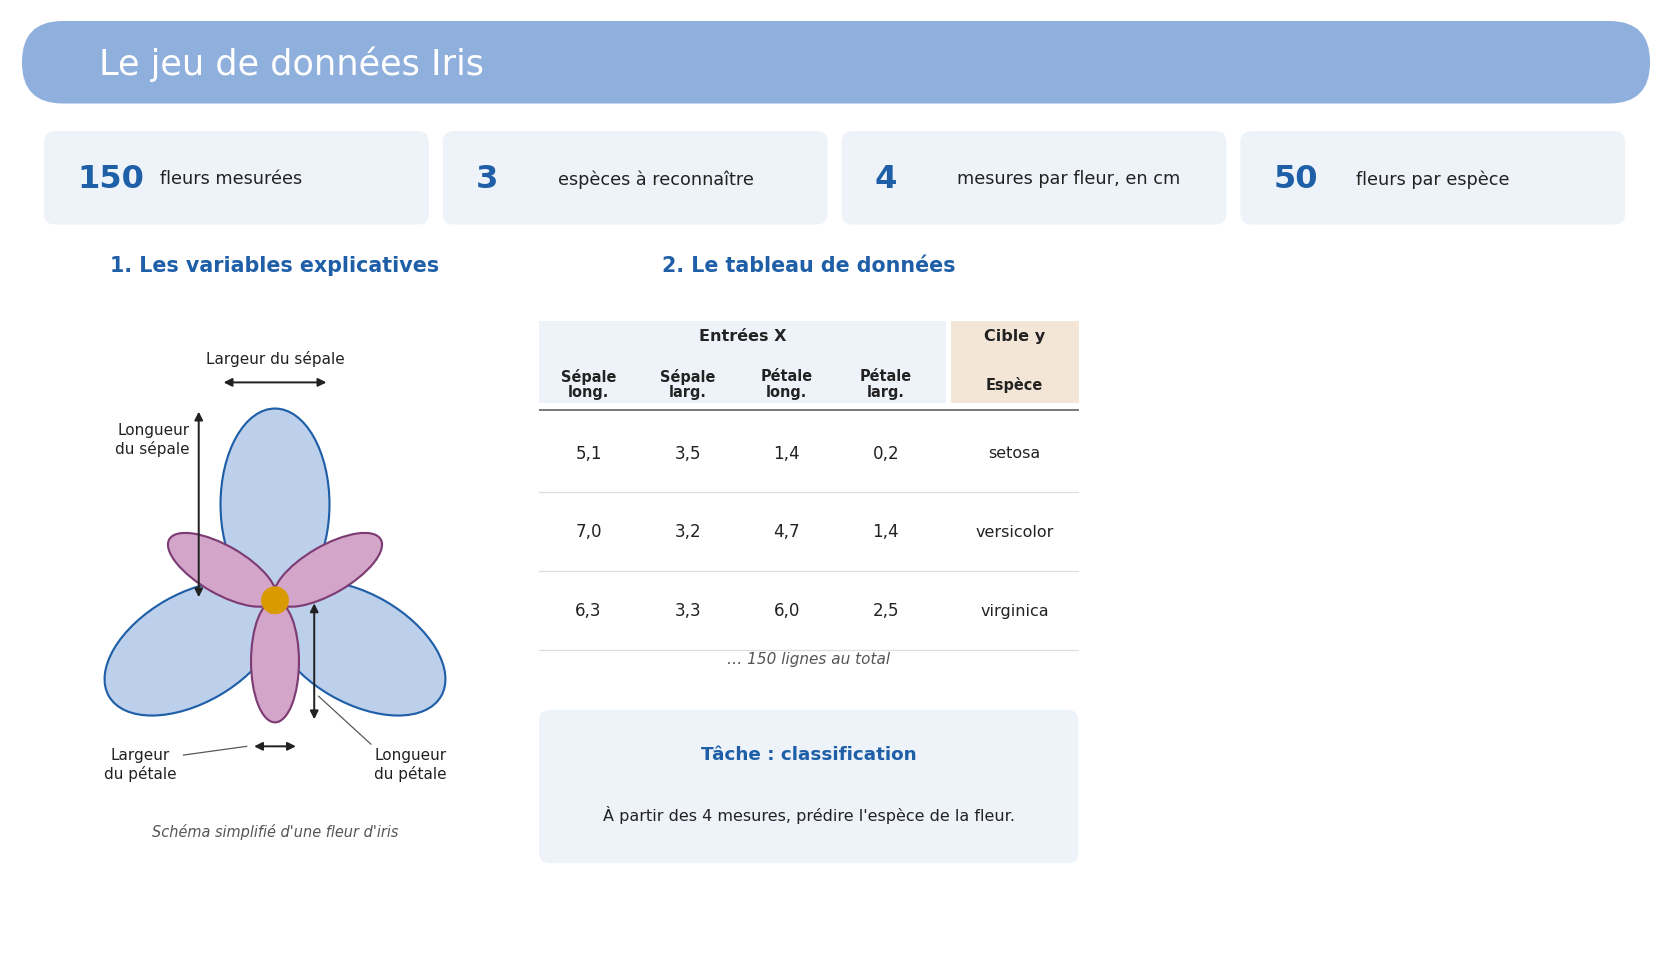

In [ ]:
# @title
import matplotlib.pyplot as plt
import numpy as np
from matplotlib.patches import Ellipse, FancyArrowPatch, FancyBboxPatch, Rectangle
from sklearn.datasets import load_iris

ENCRE, GRIS, GRILLE = "#222222", "#555555", "#dddddd"
BLEU, BLEU_CLAIR, FOND = "#1f5fa8", "#8fb0dd", "#eef3fa"
COULEURS = ("#c8372d", "#1f5fa8", "#d99a00")
MARQUEURS = ("o", "s", "^")

# Chargement des vraies données Iris
iris = load_iris()
X, y = iris.data, iris.target
especes = iris.target_names

fig = plt.figure(figsize=(15, 8.6))
fond = fig.add_axes([0, 0, 1, 1], zorder=-1)
fond.set_xlim(0, 150); fond.set_ylim(0, 86); fond.axis("off")

# Bandeau
fond.add_patch(FancyBboxPatch((1, 77.5), 148, 7.5, boxstyle="round,pad=0,rounding_size=3.7", fc=BLEU_CLAIR, ec="none"))
fond.text(8, 81.2, "Le jeu de données Iris", color="white", fontsize=23, va="center")

# Chiffres clés
chiffres = ((f"{X.shape[0]}", "fleurs mesurées"), (f"{len(especes)}", "espèces à reconnaître"),
            (f"{X.shape[1]}", "mesures par fleur, en cm"), (f"{np.bincount(y)[0]}", "fleurs par espèce"))
for i, (valeur, texte) in enumerate(chiffres):
    x = 3 + i * 36.25
    fond.add_patch(FancyBboxPatch((x, 66.5), 35, 8.5, boxstyle="round,pad=0,rounding_size=1", fc=FOND, ec="none"))
    fond.text(x + 3, 70.7, valeur, fontsize=21, fontweight="bold", color=BLEU, va="center")
    fond.text(x + 10.5, 70.7, texte, fontsize=11.5, color=ENCRE, va="center")

for x, l, titre in ((3, 42, "1. Les variables explicatives"), (48, 49, "2. Le tableau de données")):
    fond.text(x + l / 2, 62.3, titre, ha="center", fontsize=13.5, fontweight="bold", color=BLEU)


def cote(ax, debut, fin, texte, xy, ha="center"):
    ax.add_patch(FancyArrowPatch(debut, fin, arrowstyle="<|-|>", mutation_scale=11, color=ENCRE, lw=1.3, zorder=6))
    ax.text(*xy, texte, ha=ha, va="center", fontsize=10, color=ENCRE, zorder=7)


# Panneau 1 : schéma d'une fleur
ax = fig.add_axes([.02, .075, .28, .625])
ax.set_xlim(-5.3, 5.3); ax.set_ylim(-5.8, 6.3); ax.set_aspect("equal"); ax.axis("off")
for angle in (90, 210, 330):
    c = np.deg2rad(angle)
    ax.add_patch(Ellipse((2.2 * np.cos(c), 2.2 * np.sin(c)), 4.4, 2.5, angle=angle, fc="#bcd0ec", ec=BLEU, lw=1.4, zorder=2))
for angle in (30, 150, 270):
    c = np.deg2rad(angle)
    ax.add_patch(Ellipse((1.4 * np.cos(c), 1.4 * np.sin(c)), 2.8, 1.1, angle=angle, fc="#d3a6c9", ec="#7d3c74", lw=1.4, zorder=3))
ax.add_patch(plt.Circle((0, 0), .32, fc="#d99a00", ec="none", zorder=4))

# Cotes : sépale du haut et pétale du bas
cote(ax, (-1.75, 0), (-1.75, 4.4), "Longueur\ndu sépale", (-1.95, 3.7), ha="right")
cote(ax, (-1.25, 5), (1.25, 5), "Largeur du sépale", (0, 5.55))
cote(ax, (.9, -2.8), (.9, 0), "", (0, 0))
ax.text(3.1, -3.75, "Longueur\ndu pétale", ha="center", va="center", fontsize=10, color=ENCRE)
ax.plot([1.0, 2.2], [-2.2, -3.3], color=GRIS, lw=.8, zorder=6)
cote(ax, (-.55, -3.35), (.55, -3.35), "", (0, 0))
ax.text(-3.1, -3.75, "Largeur\ndu pétale", ha="center", va="center", fontsize=10, color=ENCRE)
ax.plot([-.65, -2.1], [-3.35, -3.55], color=GRIS, lw=.8, zorder=6)
ax.text(0, -5.4, "Schéma simplifié d'une fleur d'iris", ha="center", fontsize=9.5, style="italic", color=GRIS)

# Panneau 2 : extrait du tableau (une fleur réelle de chaque espèce)
ax = fig.add_axes([.32, .075, .327, .625])
ax.set_xlim(0, 49); ax.set_ylim(0, 54); ax.axis("off")
ax.add_patch(Rectangle((0, 44), 37, 7.5, fc=FOND, ec="none"))
ax.add_patch(Rectangle((37.4, 44), 11.6, 7.5, fc="#f4e6d7", ec="none"))
ax.text(18.5, 49.8, "Entrées X", ha="center", fontsize=10.5, fontweight="bold", color=ENCRE)
ax.text(43.2, 49.8, "Cible y", ha="center", fontsize=10.5, fontweight="bold", color=ENCRE)
colonnes = [(4.5, "Sépale\nlong."), (13.5, "Sépale\nlarg."), (22.5, "Pétale\nlong."), (31.5, "Pétale\nlarg."), (43.2, "Espèce")]
for x, nom in colonnes:
    ax.text(x, 45.8, nom, ha="center", va="center", fontsize=9.5, fontweight="bold", color=ENCRE, linespacing=1.05)
ax.plot([0, 49], [43.4, 43.4], color=GRIS, lw=1)
for r, i in enumerate((0, 50, 100)):
    ligne = 39.5 - r * 7.2
    for (x, _), valeur in zip(colonnes[:4], X[i]):
        ax.text(x, ligne, f"{valeur:.1f}".replace(".", ","), ha="center", va="center", fontsize=11, color=ENCRE)
    ax.text(43.2, ligne, especes[y[i]], ha="center", va="center", fontsize=10.5, color=ENCRE)
    ax.plot([0, 49], [ligne - 3.6] * 2, color=GRILLE, lw=.8)
ax.text(24.5, 20.3, f"… {X.shape[0]} lignes au total", ha="center", fontsize=10, style="italic", color=GRIS)
ax.add_patch(FancyBboxPatch((0, 2), 49, 14, boxstyle="round,pad=0,rounding_size=1", fc=FOND, ec="none"))
ax.text(24.5, 12, "Tâche : classification", ha="center", va="center", fontsize=12, fontweight="bold", color=BLEU)
ax.text(24.5, 6.5, "À partir des 4 mesures, prédire l'espèce de la fleur.",
        ha="center", va="center", fontsize=10.5, color=ENCRE)

# Panneau 3 : pétales, seules variables reprises ici pour rester lisible
# ax = fig.add_axes([.712, .165, .27, .535])
# longueur, largeur = X[:, 2], X[:, 3]
# for k, nom in enumerate(especes):
#     m = y == k
#     ax.scatter(longueur[m], largeur[m], s=46, c=COULEURS[k], marker=MARQUEURS[k],
#                edgecolors="white", linewidths=.8, label=nom, zorder=3)
# ax.set_xlabel("Longueur du pétale (cm)", fontsize=10.5, color=GRIS)
# ax.set_ylabel("Largeur du pétale (cm)", fontsize=10.5, color=GRIS)
# ax.tick_params(colors=GRIS, labelsize=9, length=0)
# ax.grid(color=GRILLE, lw=.7); ax.set_axisbelow(True)
# for cote_ax in ("top", "right"):
#     ax.spines[cote_ax].set_visible(False)
# for cote_ax in ("left", "bottom"):
#     ax.spines[cote_ax].set_color(GRILLE)
# ax.legend(loc="upper left", frameon=False, fontsize=10.5)
# fond.text(123.5, 5.2, "setosa se sépare nettement ;\nversicolor et virginica se chevauchent un peu.",
#           ha="center", va="center", fontsize=10, color=ENCRE, linespacing=1.2)

plt.savefig("iris_presentation.png", dpi=170, facecolor="white")
plt.show()

In [ ]:
iris = load_iris() # Charger les donnees
df = pd.DataFrame(iris.data, columns=["long. sépale", "larg. sépale", "long. pétale", "larg. pétale"])
df["espèce"] = [iris.target_names[i] for i in iris.target]
df.sample(6, random_state=1)

,long. sépale,larg. sépale,long. pétale,larg. pétale,espèce
14,5.8,4.0,1.2,0.2,setosa
98,5.1,2.5,3.0,1.1,versicolor
75,6.6,3.0,4.4,1.4,versicolor
16,5.4,3.9,1.3,0.4,setosa
131,7.9,3.8,6.4,2.0,virginica
56,6.3,3.3,4.7,1.6,versicolor


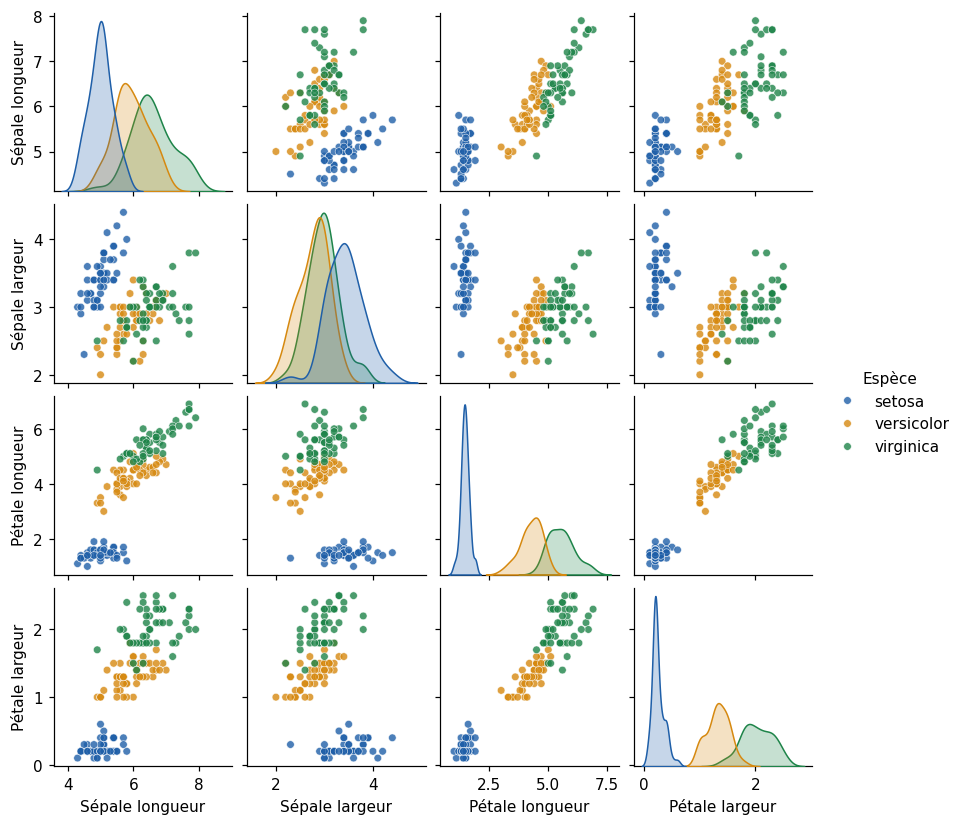

In [ ]:
# @title
import seaborn as sns

# Tableau avec des noms de colonnes en français
colonnes = ["Sépale longueur", "Sépale largeur", "Pétale longueur", "Pétale largeur"]
df = pd.DataFrame(iris.data, columns=colonnes)
df["Espèce"] = iris.target_names[iris.target]

# Matrice de nuages de points : chaque paire de variables, et chaque variable seule sur la diagonale
sns.pairplot(df, hue="Espèce", palette=couleurs, height=1.9, plot_kws={"alpha": 0.8, "s": 25})
plt.show()

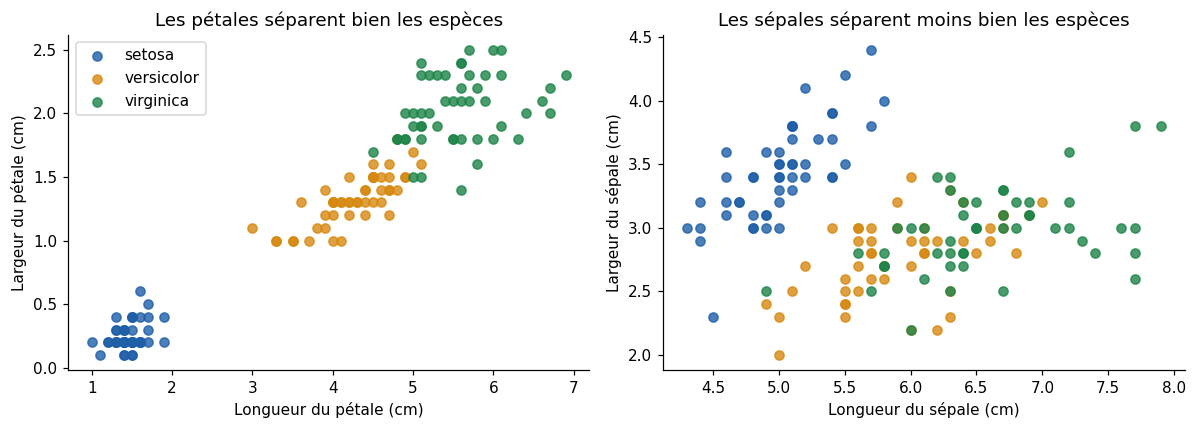

In [ ]:
couleurs = ["#1f5fa8", "#d68910", "#1e8449"]
fig, axes = plt.subplots(1, 2, figsize=(11, 4), sharey=False)

# Chaque graphique utilise une paire de mesures : (colonne x, colonne y, étiquettes, titre)
paires = [
    (2, 3, "Longueur du pétale (cm)", "Largeur du pétale (cm)", "Les pétales séparent bien les espèces"),
    (0, 1, "Longueur du sépale (cm)", "Largeur du sépale (cm)", "Les sépales séparent moins bien les espèces"),
]
for ax, (col_x, col_y, label_x, label_y, titre) in zip(axes, paires):
    for i, nom in enumerate(iris.target_names):
        sel = iris.target == i
        ax.scatter(iris.data[sel, col_x], iris.data[sel, col_y], color=couleurs[i], label=nom, alpha=0.8)
    ax.set_xlabel(label_x); ax.set_ylabel(label_y); ax.set_title(titre)
axes[0].legend()
plt.tight_layout(); plt.show()

**Observation.** Les mesures des pétales séparent mieux les espèces que celles des sépales.

- **Pétales :** *setosa* est complètement isolée. *Versicolor* et *virginica* forment deux groupes distincts, avec un léger chevauchement à leur frontière.
- **Sépales :** *setosa* reste assez bien séparée, mais *versicolor* et *virginica* sont fortement mélangées.

Un algorithme comme les k plus proches voisins profitera donc davantage des mesures des pétales. Toutes les variables n'apportent pas la même information : le choix des variables influence directement la performance d'un modèle.

## 2. Séparer entraînement et test

Comme établi au notebook 1, on réserve des données pour estimer la généralisation. On conserve ici 25 % des fleurs comme ensemble de test.

- `stratify=y` conserve la proportion de chaque classe dans les deux ensembles ;
- `random_state=0` rend le découpage reproductible.

In [ ]:
X = iris.data[:, 2:]          # deux variables seulement, afin de pouvoir visualiser
y = iris.target
X_ent, X_test, y_ent, y_test = train_test_split(X, y, test_size=0.25, stratify=y, random_state=0)
print(f"Entraînement : {len(X_ent)} observations | Test : {len(X_test)} observations")

Entraînement : 112 observations | Test : 38 observations


## 3. L'algorithme des k plus proches voisins (KNN)

Pour classer une nouvelle observation, le KNN identifie les **k observations d'entraînement les plus proches** (distance euclidienne) et attribue la classe **majoritaire** parmi elles.

- Le KNN ne possède pas de paramètres estimés par optimisation : il conserve les données d'entraînement.
- `k` est un **hyperparamètre** : un réglage fixé avant l'entraînement.

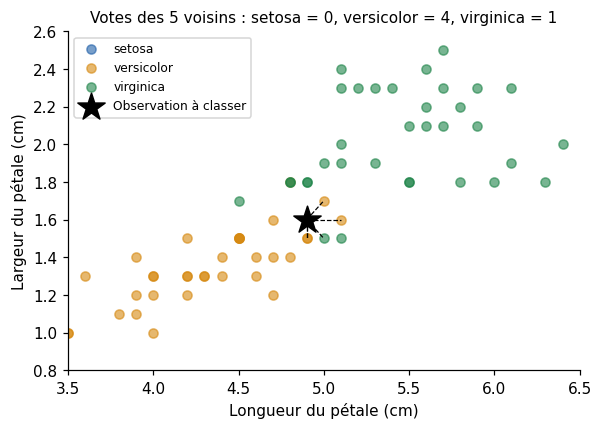

In [ ]:
nouvelle = np.array([[4.9, 1.6]])
voisins = np.argsort(np.linalg.norm(X_ent - nouvelle, axis=1))[:5]  # coordonnées des 5 voisins

plt.figure(figsize=(6, 4))
for i, nom in enumerate(iris.target_names):
    sel = y_ent == i
    plt.scatter(X_ent[sel, 0], X_ent[sel, 1], color=couleurs[i], label=nom, alpha=0.6)
for v in voisins:
    plt.plot([nouvelle[0, 0], X_ent[v, 0]], [nouvelle[0, 1], X_ent[v, 1]], "k--", lw=0.8)
plt.scatter(*nouvelle[0], marker="*", s=350, color="black", label="Observation à classer")
plt.xlim(3.5, 6.5); plt.ylim(0.8, 2.6)
plt.xlabel("Longueur du pétale (cm)"); plt.ylabel("Largeur du pétale (cm)")
votes = np.bincount(y_ent[voisins], minlength=3)
plt.title("Votes des 5 voisins : " + ", ".join(f"{iris.target_names[i]} = {votes[i]}" for i in range(3)), fontsize=10)
plt.legend(fontsize=8); plt.show()

 5 voisins mais 4 positions visibles : les fleurs identiques se superposent

### Exercice 5 — Appliquer l'interface scikit-learn

Entraînez un KNN avec `k = 5`, puis calculez son **exactitude** (proportion de prédictions correctes) sur l'ensemble de test.



In [ ]:
modele = KNeighborsClassifier(n_neighbors=5)
...                                  # À COMPLÉTER : entraîner avec .fit()
predictions = ...                    # À COMPLÉTER : prédire sur X_test .predict()
exactitude = modele.score(X_test, y_test)

print("Prédictions   :", predictions[:10])
print("Valeurs réelles :", y_test[:10])
print(f"Exactitude sur l'ensemble de test : {exactitude:.1%}")

<details>
<summary><b>Afficher la solution</b> (après avoir fait l'exercice)</summary>

```python
modele = KNeighborsClassifier(n_neighbors=5)
modele.fit(X_ent, y_ent)
predictions = modele.predict(X_test)
exactitude = modele.score(X_test, y_test)

print("Prédictions   :", predictions[:10])
print("Valeurs réelles :", y_test[:10])
print(f"Exactitude sur l'ensemble de test : {exactitude:.1%}")
```

</details>

## 4. La frontière de décision

En prédisant la classe de chaque point du plan, on visualise les **régions de décision** apprises par le modèle. Leur limite est la **frontière de décision**.

**Prédiction.** Avec `k = 1`, la frontière sera-t-elle plus régulière ou plus irrégulière qu'avec `k = 30` ? Quel réglage obtiendra la meilleure exactitude sur l'entraînement ?

In [ ]:
from matplotlib.colors import ListedColormap

def tracer_frontiere(k=5):
    m = KNeighborsClassifier(n_neighbors=k).fit(X_ent, y_ent)
    xx, yy = np.meshgrid(np.linspace(0.5, 7.5, 300), np.linspace(-0.2, 2.8, 300))
    zz = m.predict(np.c_[xx.ravel(), yy.ravel()]).reshape(xx.shape)
    plt.figure(figsize=(6, 4))
    plt.contourf(xx, yy, zz, alpha=0.25, cmap=ListedColormap(couleurs))
    for i, nom in enumerate(iris.target_names):
        plt.scatter(X_ent[y_ent == i, 0], X_ent[y_ent == i, 1], color=couleurs[i], edgecolor="k", s=25, label=nom)
    plt.xlabel("Longueur du pétale (cm)"); plt.ylabel("Largeur du pétale (cm)")
    plt.title(f"k = {k} | exactitude entraînement : {m.score(X_ent, y_ent):.0%} | test : {m.score(X_test, y_test):.0%}")
    plt.legend(fontsize=8, loc="upper left"); plt.show()

interact(tracer_frontiere, k=IntSlider(min=1, max=60, step=1, value=1, description="k"));

interactive(children=(IntSlider(value=1, description='k', max=60, min=1), Output()), _dom_classes=('widget-int…

- **k = 1 :** chaque observation d'entraînement est sa propre voisine ; l'exactitude d'entraînement est de 100 % et la frontière suit les points isolés. Risque de **surapprentissage**.
- **k très grand :** le modèle tend vers la classe majoritaire ; risque de **sous-apprentissage**.
- La valeur appropriée se situe entre les deux. Le notebook 4 présente une méthode rigoureuse pour la choisir.

## 5. Application : classification de vins

Le jeu de données `load_wine` décrit 178 vins de 3 cultivars par **13 analyses chimiques** (alcool, acidité, intensité de la couleur, proline, etc.).

### Exercice 6a — Appliquer la démarche complète

Découpez les données (25 % en test, stratification, `random_state=0`), entraînez un KNN avec `k = 5` et calculez l'exactitude sur le test.

In [ ]:
vins = load_wine()
X_vin, y_vin = vins.data, vins.target

Xv_ent, Xv_test, yv_ent, yv_test = ...   # À COMPLÉTER

knn_vin = ...                            # À COMPLÉTER

print(f"Exactitude sur les vins : {...:.1%}")

<details>
<summary><b>Afficher la solution</b> (après avoir fait l'exercice)</summary>

```python
vins = load_wine()
X_vin, y_vin = vins.data, vins.target

Xv_ent, Xv_test, yv_ent, yv_test = train_test_split(
    X_vin, y_vin, test_size=0.25, stratify=y_vin, random_state=0)

knn_vin = KNeighborsClassifier(n_neighbors=5).fit(Xv_ent, yv_ent)

print(f"Exactitude sur les vins : {knn_vin.score(Xv_test, yv_test):.1%}")
```

</details>

L'exactitude est nettement plus faible que sur les iris. Examinons l'**échelle** des variables.

In [ ]:
echelles = pd.DataFrame(load_wine().data, columns=load_wine().feature_names).agg(["min", "max"]).T
echelles.sort_values("max", ascending=False).head(5)

La **proline** varie de 278 à 1680, tandis que la **teinte** (`hue`) varie de 0,48 à 1,71. Le KNN repose sur des distances euclidiennes : une variable de grande amplitude domine toutes les autres. Le modèle se fonde presque exclusivement sur la proline.

**Normalisation.** `StandardScaler` centre et réduit chaque variable : $z = (x - \mu) / \sigma$. Chaque variable a alors une moyenne de 0 et un écart-type de 1.

**Règle méthodologique.** Les paramètres de normalisation ($\mu$, $\sigma$) doivent être estimés **sur l'ensemble d'entraînement uniquement**, sans quoi de l'information du test « fuit » dans le modèle. Un **`Pipeline`** enchaîne prétraitement et modèle, et garantit ce comportement.

### Exercice 6b — Normaliser dans un pipeline

In [ ]:
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline

pipeline_vin = make_pipeline(..., ...)   # À COMPLÉTER : normalisation, puis KNN (k = 5)
pipeline_vin.fit(Xv_ent, yv_ent)
print(f"Exactitude avec normalisation : {pipeline_vin.score(Xv_test, yv_test):.1%}")

<details>
<summary><b>Afficher la solution</b> (après avoir fait l'exercice)</summary>

```python
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline

pipeline_vin = make_pipeline(StandardScaler(), KNeighborsClassifier(n_neighbors=5))
pipeline_vin.fit(Xv_ent, yv_ent)
print(f"Exactitude avec normalisation : {pipeline_vin.score(Xv_test, yv_test):.1%}")
```

</details>

Le gain est important, sans changer d'algorithme : la **préparation des données** est souvent le premier levier d'amélioration d'un modèle.

In [ ]:
quiz("Pourquoi réserve-t-on un ensemble de test ?",
     ["Pour accélérer l'entraînement", "Pour estimer la performance sur des données non vues", "Parce que scikit-learn l'exige"],
     1, "L'ensemble de test sert à estimer la capacité de généralisation du modèle.")

In [ ]:
quiz("Où doit-on estimer la moyenne et l'écart-type utilisés par StandardScaler ?",
     ["Sur l'ensemble des données", "Sur l'ensemble d'entraînement uniquement", "Sur l'ensemble de test uniquement"],
     1, "Sinon, de l'information de l'ensemble de test influence le modèle : c'est une fuite de données. Un Pipeline évite cette erreur.")

## À retenir

- **Classification** : prédire une catégorie ; **régression** : prédire une valeur numérique.
- Démarche : `train_test_split` → instancier → `.fit()` → `.predict()` → `.score()`.
- **KNN** : vote des k plus proches voisins ; `k` est un **hyperparamètre**.
- La **frontière de décision** révèle la complexité du modèle.
- Les méthodes fondées sur des distances exigent des variables **normalisées**, à l'intérieur d'un `Pipeline`.

**Pause de 10 minutes.** Notebook suivant : 3 — Évaluer un modèle.